## 2 Pandas DataFrame

In [192]:
import pandas as pd

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


In [193]:
df = pd.read_csv("state_data.csv")

In [194]:
df.shape
print("There are 52 rows and 4 columns")

There are 52 rows and 4 columns


In [195]:
df.head()


,state,latitude,longitude,name
0,AK,63.588753,-154.493062,Alaska
1,AL,32.318231,-86.902298,Alabama
2,AR,35.201050,-91.831833,Arkansas
3,AZ,34.048928,-111.093731,Arizona
4,CA,36.778261,-119.417932,California


In [196]:
df.tail()


,state,latitude,longitude,name
47,VT,44.558803,-72.577841,Vermont
48,WA,47.751074,-120.740139,Washington
49,WI,43.784440,-88.787868,Wisconsin
50,WV,38.597626,-80.454903,West Virginia
51,WY,43.075968,-107.290284,Wyoming


In [197]:
print("Each column represents represents data from each different state. The first state is Alaska. The last state is Wyoming. There are 51 entries totoal. I'm not sure there are more than 50 states, maybe they counted some twice.")



Each column represents represents data from each different state. The first state is Alaska. The last state is Wyoming. There are 51 entries totoal. I'm not sure there are more than 50 states, maybe they counted some twice.


In [198]:
print(f"The value of the median latitude is {df["latitude"].median()}")
print(f"The value of the median longitude is {df["longitude"].median()}")


The value of the median latitude is 39.4355155
The value of the median longitude is -89.093198


In [199]:
median_latitude = df["latitude"].median()

absolute_value_distance = abs(df["latitude"] - median_latitude)

df["distance_to_median_latitude"] = absolute_value_distance 


median_longitude = df["longitude"].median()

absolute_value_distance = abs(df["longitude"] - median_longitude)

df["distance_to_median_longitude"] = absolute_value_distance


print(df.shape)

print("There are still 52 rows, but now there are 6 columns")


(52, 6)
There are still 52 rows, but now there are 6 columns


In [200]:
value_closest_to_median_latitude = df["distance_to_median_latitude"].idxmin()

state_closest_to_median_latitude = df.loc[closest_to_median_latitude, 'state']

print(f"The state closest to the median latitude is {state_closest_to_median_latitude} by {value_closest_to_median_latitude:.2f}")


value_farthest_to_median_latitude = df["distance_to_median_latitude"].idxmax()

state_farthest_to_median_latitude = df.loc[value_farthest_to_median_latitude, 'state']

print(f"The states farthest to the median latitude is {state_farthest_to_median_latitude} by {value_farthest_to_median_latitude:.2f}")

The state closest to the median latitude is CO by 5.00
The states farthest to the median latitude is AK by 0.00


In [201]:
print(df.pop("name") )

print("The .pop function retuens the selected column, thne deletes it from the data frame")

0                   Alaska
1                  Alabama
2                 Arkansas
3                  Arizona
4               California
5                 Colorado
6              Connecticut
7     District of Columbia
8                 Delaware
9                  Florida
10                 Georgia
11                  Hawaii
12                    Iowa
13                   Idaho
14                Illinois
15                 Indiana
16                  Kansas
17                Kentucky
18               Louisiana
19           Massachusetts
20                Maryland
21                   Maine
22                Michigan
23               Minnesota
24                Missouri
25             Mississippi
26                 Montana
27          North Carolina
28            North Dakota
29                Nebraska
30           New Hampshire
31              New Jersey
32              New Mexico
33                  Nevada
34                New York
35                    Ohio
36                Oklahoma
3

In [202]:
print(df.shape) 
print("You can see now there are only 5 columns whne previously there were 6")

(52, 5)
You can see now there are only 5 columns whne previously there were 6


## 3 Seaborn

In [203]:
import matplotlib.pyplot as plt
import seaborn as sns

In [204]:
df = sns.load_dataset("healthexp")
df.dropna(axis = 1)

print(f"The shape of my chosen dataset is {df.shape}, it has 274 rows and 4 columns")

The shape of my chosen dataset is (274, 4), it has 274 rows and 4 columns


In [205]:
df.tail()

,Year,Country,Spending_USD,Life_Expectancy
269,2020,Germany,6938.983,81.1
270,2020,France,5468.418,82.3
271,2020,Great Britain,5018.700,80.4
272,2020,Japan,4665.641,84.7
273,2020,USA,11859.179,77.0


In [206]:
df.head()

,Year,Country,Spending_USD,Life_Expectancy
0,1970,Germany,252.311,70.6
1,1970,France,192.143,72.2
2,1970,Great Britain,123.993,71.9
3,1970,Japan,150.437,72.0
4,1970,USA,326.961,70.9


In [207]:
for column in df.columns:
    print(column)
print('The "Year" column represents the year the data was taken in. The "Country" column tells you what country the data coreesponds to. The "Spending_USD" column I think is probably the money spent on healthcare. The "Life_Expectancy" column represents how long your expected to live in that given country in that given year.')

       

Year
Country
Spending_USD
Life_Expectancy
The "Year" column represents the year the data was taken in. The "Country" column tells you what country the data coreesponds to. The "Spending_USD" column I think is probably the money spent on healthcare. The "Life_Expectancy" column represents how long your expected to live in that given country in that given year.


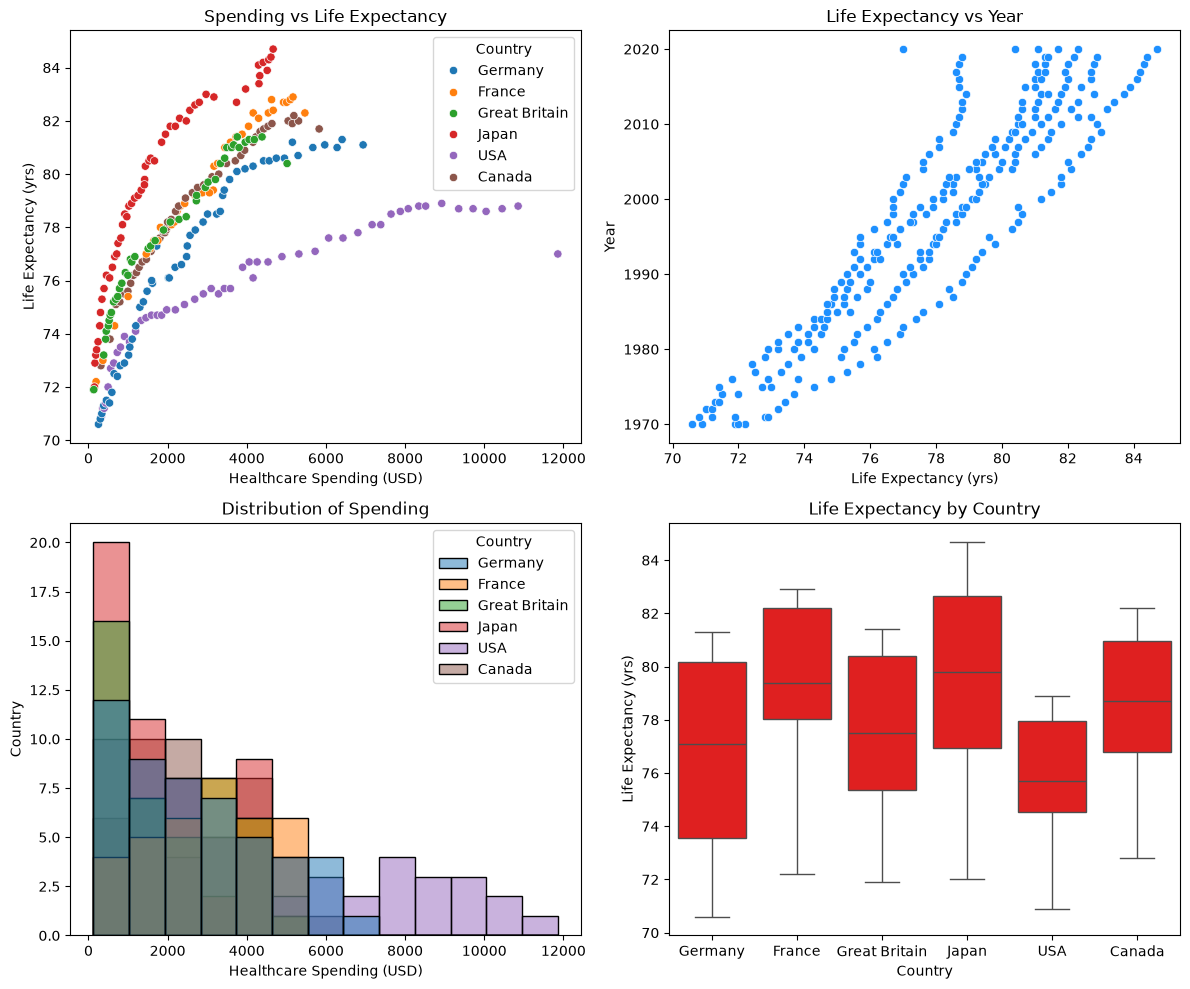

In [208]:
fig, axes = plt.subplots(2,2, figsize = (12,10))

sns.scatterplot(data = df, x = "Spending_USD", y = "Life_Expectancy", ax = axes[0, 0], hue = "Country")
axes[0, 0].set_title("Spending vs Life Expectancy")
axes[0, 0].set_xlabel("Healthcare Spending (USD)")
axes[0, 0].set_ylabel("Life Expectancy (yrs)")
axes[0, 0].legend(title="Country")

sns.scatterplot(data = df, x = "Life_Expectancy", y = "Year", ax = axes[0, 1], color = "dodgerblue")
axes[0, 1].set_title("Life Expectancy vs Year")
axes[0, 1].set_xlabel("Life Expectancy (yrs)")
axes[0, 1].set_ylabel("Year")

sns.histplot(data = df, x = "Spending_USD", hue = "Country", ax = axes[1, 0], color = "Pink")
axes[1, 0].set_title("Distribution of Spending")
axes[1, 0].set_xlabel("Healthcare Spending (USD)")
axes[1, 0].set_ylabel("Country")

sns.boxplot(data = df, x = "Country", y = "Life_Expectancy", ax = axes[1, 1], color = "Red")
axes[1, 1].set_title("Life Expectancy by Country")
axes[1, 1].set_xlabel("Country")
axes[1, 1].set_ylabel("Life Expectancy (yrs)")

plt.tight_layout()
plt.show()

In [209]:
print("The top left subplot shows how much each country is spedning on healthcare compared the life expectancy. I chose these teo column because I wanted to see if there was a correlation between living longer and money spent on healthcare. From the scatter plot you can see that the more money spend on healthere, the highet the life execantcy is.")
print("The top right subplot shows how life expectancy changes over the years. I chose theset two columns because I wanted ot see wheather life expectancy is going down or up. The scatter plot shows that life expectancy is going up.")
print("The bottom left subplot shows how much many countries, in all years, spent an interval amount of money on healthcare. I chose this because I wanted to see what range of money was spent the most. The graph shows that 0$-1000$ was spent more frequently.")
print("The bottom rigth boxplot shows how spread out the life expectancy is for each country. I chose this becsue I wanted to see how the life expectancy between each country is differnt. The graph shows that Japan has the highest average life expectancy.")



The top left subplot shows how much each country is spedning on healthcare compared the life expectancy. I chose these teo column because I wanted to see if there was a correlation between living longer and money spent on healthcare. From the scatter plot you can see that the more money spend on healthere, the highet the life execantcy is.
The top right subplot shows how life expectancy changes over the years. I chose theset two columns because I wanted ot see wheather life expectancy is going down or up. The scatter plot shows that life expectancy is going up.
The bottom left subplot shows how much many countries, in all years, spent an interval amount of money on healthcare. I chose this because I wanted to see what range of money was spent the most. The graph shows that 0$-1000$ was spent more frequently.
The bottom rigth boxplot shows how spread out the life expectancy is for each country. I chose this becsue I wanted to see how the life expectancy between each country is differnt.